Unique file counts per condition:
condition
Ripple            9
Ripple_Shuffle    9
Name: file, dtype: int64


C:\Users\Cornell\AppData\Local\Temp\ipykernel_60024\2102710847.py:163: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


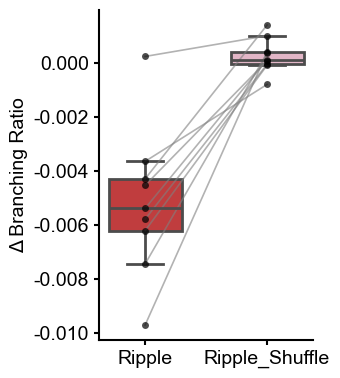

In [4]:
import os
import pickle
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import matplotlib as mpl
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match (works if those faces exist on your system)
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# --- Step 1: Load all files ---
base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\branching_ratio\ripple\changes"
files = [f for f in os.listdir(base_dir) if f.endswith("_br_changes_.pkl")]

all_rows = []

# --- Step 2: Extract results ---
import numpy as np

all_rows = []

for fname in files:
    fpath = os.path.join(base_dir, fname)
    with open(fpath, "rb") as f:
        payload = pickle.load(f)

    results = payload["results"] if isinstance(payload, dict) and "results" in payload else payload

    parts = fname.split("_")
    animal = parts[0]
    day = parts[1]

    # Collect all values first (for normalization)
    file_values = []
    for key in ["ripples_br_changes", "ripples_br_changes_shuffle",
                "barrage_br_changes", "barrage_br_changes_shuffle"]:
        if key in results:
            file_values.extend(results[key])

    file_values = np.array(file_values, dtype=float)
    mean_val = np.nanmean(file_values)
    std_val  = np.nanstd(file_values)

    # Avoid div by zero
    if std_val == 0:
        std_val = 1.0

    # Now add normalized rows
    for key, label in [
        ("ripples_br_changes", "Ripple"),
        ("ripples_br_changes_shuffle", "Ripple_Shuffle"),
        ("barrage_br_changes", "Barrage"),
        ("barrage_br_changes_shuffle", "Barrage_Shuffle"),
    ]:
        if key in results:
            vals = results[key]
            for v in vals:
                v_norm = v # z-score normalization
                all_rows.append({
                    "animal": animal,
                    "day": day,
                    "condition": label,
                    "value": v_norm
                })

# --- Step 3: Build dataframe ---
df = pd.DataFrame(all_rows)


# --- Step 1: Load all files ---
df["file"] = df["animal"].astype(str) + "_" + df["day"].astype(str)
df = df.dropna(subset=["value", "animal", "day", "condition"]).copy()
# --- Compute per-file mean per condition ---
pf = (
    df.groupby(["file", "condition"], observed=True)["value"]
      .mean()
      .rename("file_mean")
      .reset_index()
)

print("Unique file counts per condition:")
print(pf.groupby("condition")["file"].nunique())
df["file"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

pf = (
    df.groupby(["file", "condition"], observed=True)["value"]
      .mean()
      .rename("file_mean")
      .reset_index()
)
# Ripple subset
pf_ripple = pf[pf["condition"].isin(["Ripple", "Ripple_Shuffle"])].copy()
def draw_paired_lines(ax, df_pair, order, color="gray", alpha=0.5):
    """
    df_pair must contain columns: file, condition, file_mean
    """
    # Pivot to file → [cond1, cond2]
    pivot = df_pair.pivot_table(index="file", columns="condition", values="file_mean", observed=True)

    # Keep only files that have both conditions
    pivot = pivot.dropna()

    # Draw connecting lines
    for file_id, row in pivot.iterrows():
        ax.plot(
            [order[0], order[1]],
            [row[order[0]], row[order[1]]],
            color=color, alpha=alpha, linewidth=1.2
        )

# Barrage subset
pf_barrage = pf[pf["condition"].isin(["Barrage", "Barrage_Shuffle"])].copy()
pal_ripple = {"Ripple": "tab:red", "Ripple_Shuffle": "#e9afc6ff"}
order_ripple = ["Ripple", "Ripple_Shuffle"]


plt.figure(figsize=(3.5,4))
ax = plt.gca()

# --- Paired lines FIRST (so boxplot/stripplot draw over them) ---


# --- Boxplot ---
sns.boxplot(
    data=pf_ripple, x="condition", y="file_mean",
    order=order_ripple, palette=pal_ripple,
    showfliers=False, width=0.6, linewidth=2, ax=ax
)

# --- Points (stripplot) ---
sns.stripplot(
    data=pf_ripple, x="condition", y="file_mean",
    order=order_ripple, color="k", alpha=0.7,jitter=False,
     size=5, ax=ax
)

ax.set_xlabel("")
ax.set_ylabel(r"Δ Branching Ratio")
sns.despine(top=True, right=True)
draw_paired_lines(ax, pf_ripple, order_ripple, color="gray", alpha=0.6)
plt.tight_layout()

save_path1 = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig2G_ripple_br_changes_perfile_paired.svg"
plt.savefig(save_path1, dpi=300)
plt.show()


In [6]:
import statsmodels.formula.api as smf
import numpy as np
from scipy.stats import norm

# ---------------------------------------
# 0) Ensure IDs
# ---------------------------------------
df = df.copy()
df["animal"] = df["animal"].astype(str)
df["day"]    = df["day"].astype(str)
df["animal_day"] = df["animal"] + "_" + df["day"]

# ---------------------------------------
# 1) Collapse to means (per file × condition)
# ---------------------------------------
df_mean = (
    df.dropna(subset=["value", "condition", "animal_day", "animal"])
      .groupby(["animal", "animal_day", "condition"], as_index=False)
      .agg(value=("value", "mean"),
           n=("value", "size"))
)

print("Rows in df_mean:", len(df_mean))
print("Unique animal_day:", df_mean["animal_day"].nunique())
print("Counts per condition:\n", df_mean["condition"].value_counts())

# OPTIONAL but often good: keep only paired animal_days that have BOTH conditions
pivot = df_mean.pivot_table(index="animal_day", columns="condition", values="value", aggfunc="mean")
paired_days = pivot.dropna().index
df_mean = df_mean[df_mean["animal_day"].isin(paired_days)].copy()
print("Paired animal_day kept:", df_mean["animal_day"].nunique())

# ---------------------------------------
# 2) Mixed model on means
#   groups = animal_day (pairing)
#   + animal variance component
# ---------------------------------------
model = smf.mixedlm(
    "value ~ C(condition)",
    data=df_mean,
    groups=df_mean["animal_day"],
    vc_formula={"animal": "0 + C(animal)"}
)

res = model.fit(method="lbfgs")
print(res.summary())

# ---------------------------------------
# 3) Contrast (same as before)
# ---------------------------------------
fe = res.fe_params
cov_fe = res.cov_params().loc[fe.index, fe.index]

def contrast_test(coeffs: dict, label: str):
    c = np.zeros(len(fe))
    for i, name in enumerate(fe.index):
        if name in coeffs:
            c[i] = coeffs[name]
    diff = float(c @ fe.values)
    se   = float(np.sqrt(c @ cov_fe.values @ c))
    z    = diff / se
    p    = 2 * norm.sf(abs(z))
    print(f"{label}: diff={diff:.6g}, z={z:.3f}, p={p:.4g}")
    return diff, p

contrast_test(
    {"C(condition)[T.Ripple]": 1, "C(condition)[T.Ripple_Shuffle]": -1},
    "Ripple vs Ripple_Shuffle (session means)"
)


Rows in df_mean: 18
Unique animal_day: 9
Counts per condition:
 condition
Ripple            9
Ripple_Shuffle    9
Name: count, dtype: int64
Paired animal_day kept: 9
                  Mixed Linear Model Regression Results
Model:                    MixedLM       Dependent Variable:       value  
No. Observations:         18            Method:                   REML   
No. Groups:               9             Scale:                    0.0000 
Min. group size:          2             Log-Likelihood:           66.7255
Max. group size:          2             Converged:                Yes    
Mean group size:          2.0                                            
-------------------------------------------------------------------------
                               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------------------
Intercept                      -0.005    0.002 -2.775 0.006 -0.009 -0.002
C(condition)[T.Ripple_Shuffle]  0.005 

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1533: RuntimeWarning: divide by zero encountered in log
  cov_aug_logdet = cov_re_logdet + np.sum(np.log(vc_var))
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1537: RuntimeWarning: divide by zero encountered in divide
  solver = _smw_solver(1., ex_r, ex2_r, cov_re_inv, 1 / vc_var)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1542: RuntimeWarning: divide by zero encountered in divide
  ld = _smw_logdet(1., ex_r, ex2_r, cov_re_inv, 1 / vc_var,
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:573: RuntimeWarning: invalid value encountered in scalar add
  return B_logdet + ld + ld1
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects 

(-0.005462023655091633, 1.5464815040508354e-17)